Equació utilitzada per a generar les dades: y = 3X³ - 2X² + 5sin(5X) + 2cos(3X) + soroll
[2.53124541]
[1.         2.53124541 6.40720333]


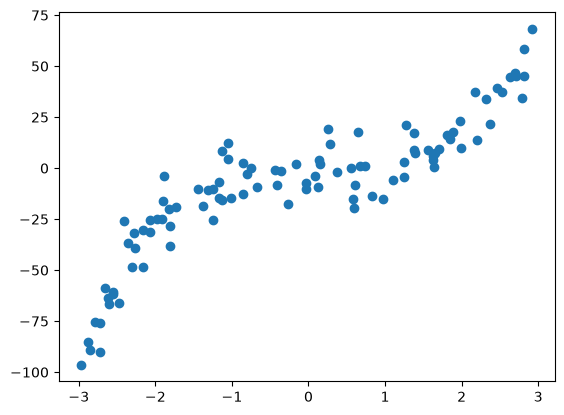

In [1]:
# Importar les biblioteques necessàries
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Generar dades altament no lineals i extremadament sorolloses
np.random.seed(42)  # Fixar una llavor per a la reproductibilitat
X = np.random.uniform(-3, 3, size=(100, 1))  # Generar valors uniformes entre -3 i 3

# Introduir termes complexos no lineals amb soroll significatiu
y = 3 * X**3 - 2 * X**2 + 5 * np.sin(5 * X) + 2 * np.cos(3 * X) + np.random.normal(0, 10, size=X.shape)

# Imprimir l'equació utilitzada per a generar les dades
print("Equació utilitzada per a generar les dades: y = 3X³ - 2X² + 5sin(5X) + 2cos(3X) + soroll")

# Dividir les dades en conjunts d'entrenament i prova
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)  # 80% entrenament, 20% prova

poly = PolynomialFeatures(2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train[0])
print(X_train_poly[0])

plt.scatter(X,y)

Equació utilitzada per a generar les dades: y = 3X³ - 2X² + 5sin(5X) + 2cos(3X) + soroll


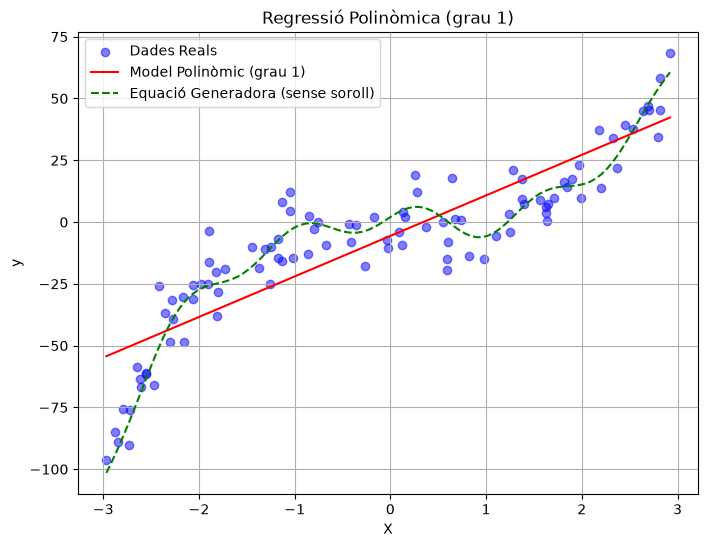

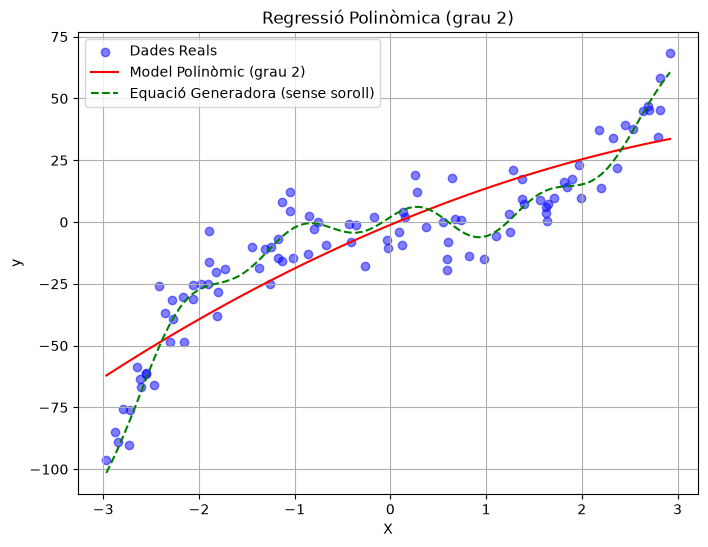

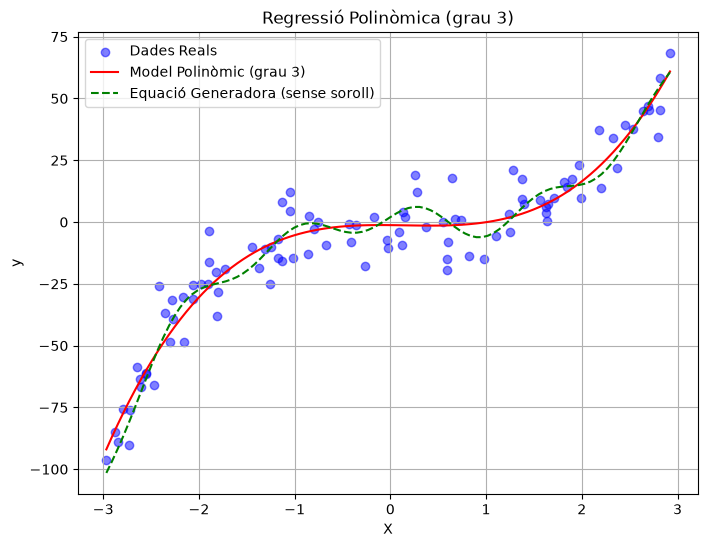

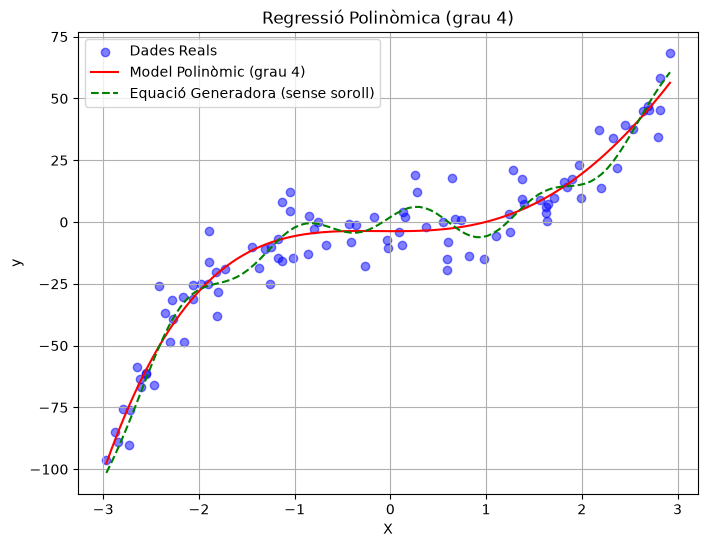

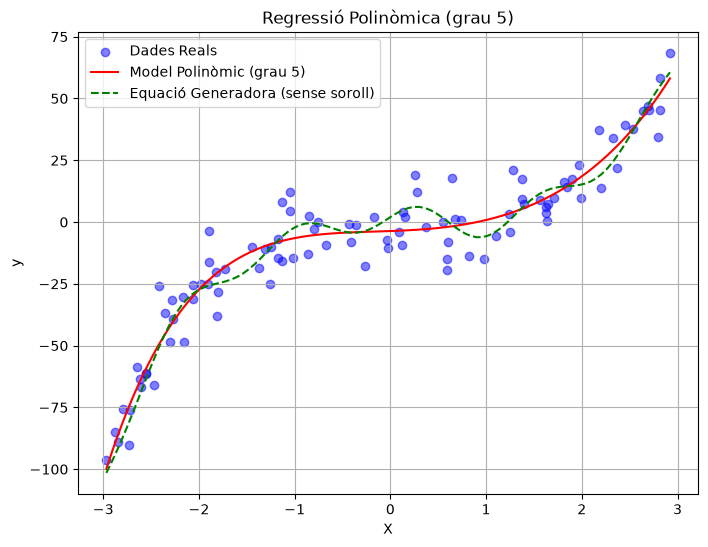


Resultats dels models de regressió polinòmica (ordenats per R²):
 Grau        MSE      RMSE       R²
    3  61.090895  7.816066 0.942471
    5  61.637941  7.850983 0.941956
    4  62.967623  7.935214 0.940704
    2 212.026983 14.561146 0.800336
    1 248.273153 15.756686 0.766203


In [1]:
# Provar diferents graus de polinomis
degrees = [1, 2, 3, 4, 5]  # Graus a avaluar
results = []  # Llista per a emmagatzemar els resultats de cada grau

for degree in degrees:
    # Transformar les característiques amb PolynomialFeatures
    poly = PolynomialFeatures(degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Crear i entrenar el model de regressió lineal
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Generar prediccions en el conjunt de prova
    y_pred = model.predict(X_test_poly)

    # Calcular mètriques finals en el conjunt de prova
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Emmagatzemar els resultats
    results.append((degree, mse, rmse, r2))

    # Graficar el model de cada grau
    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    X_range_poly = poly.transform(X_range)
    y_range_pred = model.predict(X_range_poly)

    plt.figure(figsize=(8, 6))
    plt.scatter(X, y, color='blue', alpha=0.5, label="Dades Reals")
    plt.plot(X_range, y_range_pred, color="red", label=f"Model Polinòmic (grau {degree})")

    y_generated_range = 3 * X_range**3 - 2 * X_range**2 + 5 * np.sin(5 * X_range) + 2 * np.cos(3 * X_range)
    plt.plot(X_range, y_generated_range, color='green', linestyle='--', label='Equació Generadora (sense soroll)')
    plt.title(f"Regressió Polinòmica (grau {degree})")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.legend()
    plt.grid()
    plt.show()

# Crear un DataFrame amb els resultats i ordenar-los per R² de prova
results_df = pd.DataFrame(results, columns=["Grau", "MSE", "RMSE", "R²"]).sort_values(by="R²", ascending=False)

# Imprimir els resultats ordenats
print("\nResultats dels models de regressió polinòmica (ordenats per R²):")
print(results_df.to_string(index=False))  # Mostrar taula completa sense truncar